# Stacking and model choice: does combining logistic regression and KNN help?

**Research question:** what factors can predict whether or not adolescents cross the clinical threshold for depression according to the BDI-II?

The group's notes for the second presentation left two options for the final model:
1. pick one model (logistic regression or KNN), or
2. use an ensemble method, **stacking**, to combine both.

This notebook tests option 2 and then compiles the evidence for the final choice. It applies the Week 8 ensemble material (`01_week8_EnsembleMethods_Forest.ipynb` and the stacking slides) and follows the same evaluation steps as `evaluation.ipynb`: validation set, 5-fold cross-validation, and one final check on the test set. Following the group's decision, models are compared on **F1**, because the classes are imbalanced.

**Learning goals (from Week 8), applied here**
- Explain how stacking combines base models through a meta-learner.
- Train the meta-learner on out-of-fold predictions to avoid leakage.
- Compare the stacked model with its base models fairly.
- Choose a model with validation data and cross-validation, not the test set.

---
## Step 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score,
)

# Fixing the random seed makes the splits, folds and models reproducible
RANDOM_STATE = 42

---
## Step 2. Load data, define target and features

Same file, target and seven features as the other model notebooks.

In [2]:
df = pd.read_csv("../data/processed/model_ready.csv")

feature_cols = [
    "screen_time_index", "est_leisure_screen_hours", "sex_binary",
    "sleep_quality_index", "avg_sleep_hours",
    "midsleep_weekend_hours", "social_jetlag_hours",
]
target = "depressed"   # 1 = BDI-II total >= 14, 0 = below

X = df[feature_cols]
y = df[target].astype(int)

print("X shape:", X.shape)
print(y.value_counts(normalize=True).rename({0: "not depressed", 1: "depressed"}).round(3))

X shape: (4810, 7)
depressed
not depressed    0.836
depressed        0.164
Name: proportion, dtype: float64


---
## Step 3. Training, validation and test sets

The same two-stage split as `evaluation.ipynb`, so the results can be compared directly:
1. The same 80/20 split as the other model notebooks (seed 42): the test set is the same 962 adolescents.
2. The remaining 80% is split into training (60% of all data) and validation (20%), stratified by the target.

In [3]:
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_trainval, y_trainval, test_size=0.25,
    random_state=RANDOM_STATE, stratify=y_trainval
)

for name, part in [("Train", y_train), ("Validation", y_valid), ("Test", y_test)]:
    print(f"{name:11s}{len(part):5d} rows   depressed: {part.sum():3d} ({part.mean():.1%})")

Train       2886 rows   depressed: 481 (16.7%)
Validation   962 rows   depressed: 160 (16.6%)
Test         962 rows   depressed: 146 (15.2%)


---
## Step 4. Build the stacked model

**Stacking** (Wolpert, 1992) is the third ensemble approach from Week 8, next to bagging and boosting:
- **Base models:** different algorithms trained on the same data. Here: logistic regression and KNN (k = 5), each with the same settings as in their own notebooks and inside a `Pipeline` with a `StandardScaler`.
- **Meta-learner:** a second model that takes the base models' predicted probabilities as its inputs and learns how much to trust each one. Here: a logistic regression, as suggested on the Week 8 slides.

**Avoiding leakage.** If the meta-learner were trained on base-model predictions for rows those models had already seen, it would learn from overconfident, in-sample predictions. Instead it is trained on **out-of-fold predictions**: the training data is split into 5 folds, each base model predicts each fold after being trained on the other four, and these predictions are the meta-learner's training data (`cv=5` in `StackingClassifier`).

In [4]:
def make_logreg():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])

def make_knn():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])

def make_stack():
    return StackingClassifier(
        estimators=[("logreg", make_logreg()), ("knn", make_knn())],
        final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),  # out-of-fold predictions
        stack_method="predict_proba",   # the meta-learner sees each base model's probability of 'depressed'
    )

model_makers = {
    "Logistic regression": make_logreg,
    "KNN (k = 5)": make_knn,
    "Stacking (logistic regression + KNN)": make_stack,
}
print("Models to compare:", list(model_makers))

Models to compare: ['Logistic regression', 'KNN (k = 5)', 'Stacking (logistic regression + KNN)']


---
## Step 5. Compare the three models on the validation set

Each model is trained on the training set and scored on the validation set. The test set is not touched.

In [5]:
def scores(y_true, pred):
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "Flagged as depressed": int(pred.sum()),
        "Real cases caught": int(((pred == 1) & (y_true == 1)).sum()),
    }

fitted = {}
validation_rows = {}
for name, make in model_makers.items():
    model = make().fit(X_train, y_train)
    fitted[name] = model
    validation_rows[name] = {
        "Training accuracy": accuracy_score(y_train, model.predict(X_train)),
        **scores(y_valid, model.predict(X_valid)),
    }

validation_results = pd.DataFrame(validation_rows).T
print(f"Validation baseline (always 'not depressed'): {(y_valid == 0).mean():.3f}")
print(f"Real cases in the validation set: {int(y_valid.sum())}")
validation_results.round(3)

Validation baseline (always 'not depressed'): 0.834
Real cases in the validation set: 160


,Training accuracy,Accuracy,Precision,Recall,F1,Flagged as depressed,Real cases caught
Logistic regression,0.839,0.843,0.610,0.156,0.249,41.0,25.0
KNN (k = 5),0.855,0.823,0.424,0.175,0.248,66.0,28.0
Stacking (logistic regression + KNN),0.840,0.843,0.622,0.144,0.234,37.0,23.0


## **Explanation**

- **Stacking does not beat either base model on the validation set.** Its F1 is 0.234, against 0.249 for logistic regression and 0.248 for KNN.
- **It behaves almost exactly like logistic regression, only slightly more cautious.** It flags 37 adolescents (logistic regression 41) and catches 23 of the 160 real cases (logistic regression 25). Its precision is the highest of the three (0.622), because it flags the fewest.
- **It does not inherit KNN's higher recall.** KNN catches 28 real cases; the stack catches 23.
- **No model is overfitting:** training accuracy is within about 0.03 of validation accuracy for all three (KNN has the largest gap, 0.855 against 0.823).
- Accuracy is close to the 0.834 baseline for every model, as in the other notebooks.

---
## Step 6. Inside the stack: how much does the meta-learner trust each model?

The meta-learner is a logistic regression with one input per base model, so its two coefficients show how much weight it gives each base model's probability.

Stacking works best when the base models are strong **and make different mistakes**. The second part of the cell checks how similar the two base models' out-of-fold probabilities are.

Meta-learner coefficients:
P(depressed) from logistic regression    4.564
P(depressed) from KNN                    0.529
Meta-learner intercept: -2.615

Correlation between the two models' out-of-fold probabilities: 0.637
KNN probabilities take only these values (k = 5 neighbours voting): [np.float64(0.0), np.float64(0.2), np.float64(0.4), np.float64(0.6), np.float64(0.8), np.float64(1.0)]


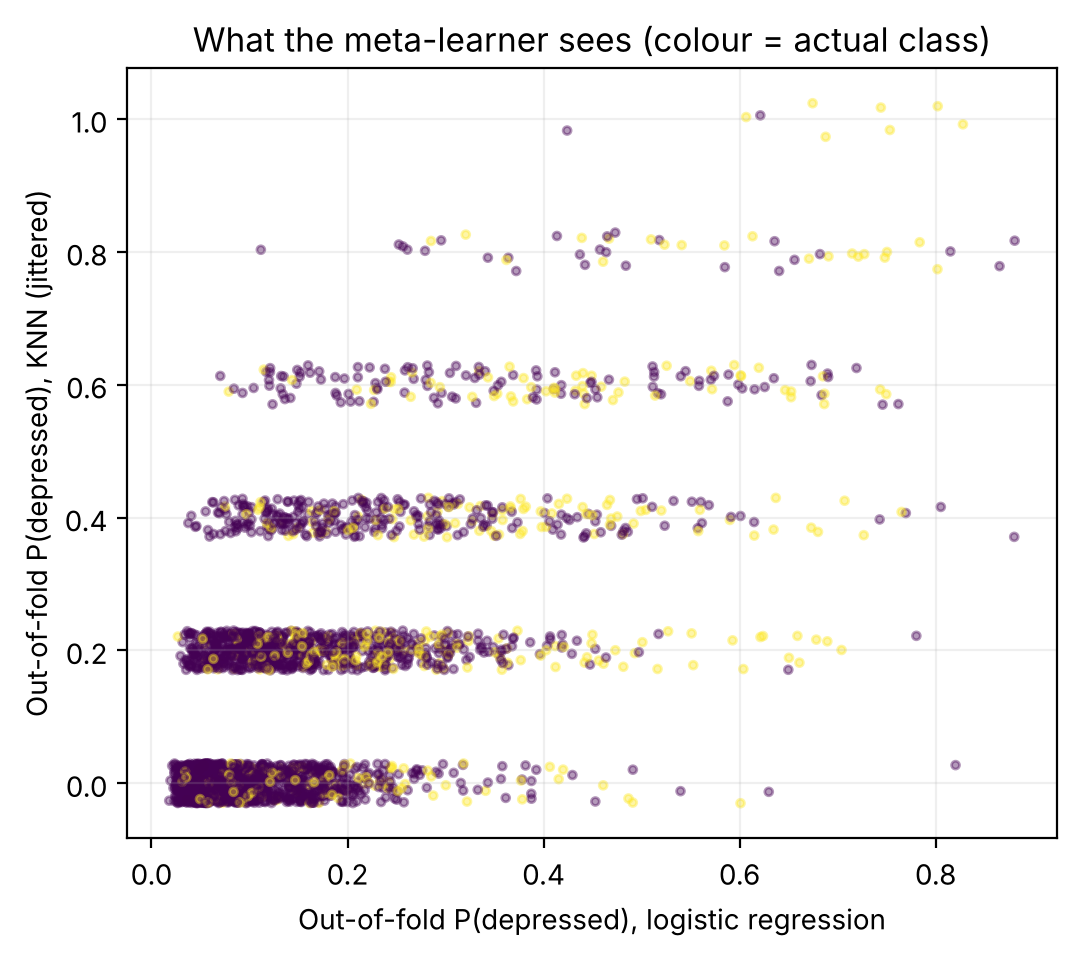

In [6]:
stack = fitted["Stacking (logistic regression + KNN)"]
meta = stack.final_estimator_

weights = pd.Series(meta.coef_[0], index=["P(depressed) from logistic regression", "P(depressed) from KNN"])
print("Meta-learner coefficients:")
print(weights.round(3).to_string())
print(f"Meta-learner intercept: {meta.intercept_[0]:.3f}\n")

# Out-of-fold probabilities of each base model on the training set (the meta-learner's inputs)
oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof = pd.DataFrame({
    "Logistic regression": cross_val_predict(make_logreg(), X_train, y_train, cv=oof_cv, method="predict_proba")[:, 1],
    "KNN (k = 5)": cross_val_predict(make_knn(), X_train, y_train, cv=oof_cv, method="predict_proba")[:, 1],
})
print(f"Correlation between the two models' out-of-fold probabilities: {oof.corr().iloc[0, 1]:.3f}")
print("KNN probabilities take only these values (k = 5 neighbours voting):", sorted(oof["KNN (k = 5)"].unique()))

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(oof["Logistic regression"], oof["KNN (k = 5)"] + np.random.default_rng(0).uniform(-0.03, 0.03, len(oof)),
           c=y_train.values, s=8, alpha=0.4)
ax.set_xlabel("Out-of-fold P(depressed), logistic regression")
ax.set_ylabel("Out-of-fold P(depressed), KNN (jittered)")
ax.set_title("What the meta-learner sees (colour = actual class)")
ax.grid(alpha=0.2)
plt.show()

## **Explanation**

- **The meta-learner puts almost all its weight on logistic regression:** a coefficient of 4.56 for logistic regression's probability against 0.53 for KNN's. The stacked model is close to logistic regression with a small adjustment from KNN.
- **Why it learns this:** KNN's probability can only take six values (0, 0.2, 0.4, 0.6, 0.8 or 1), because it is the share of 5 neighbours who are depressed. Logistic regression gives a smooth probability that ranks adolescents more finely, so it is more useful to the meta-learner.
- **The two models agree only moderately** (correlation 0.64), so they do make some different mistakes. But the plot shows that where they disagree, KNN is not reliably right: the band at a KNN probability of 0.6 contains many adolescents who are not depressed (purple) despite a low logistic regression probability. KNN's extra information is mostly noise, so the meta-learner learns to largely ignore it.
- Stacking helps when the base models are strong and make different mistakes for good reasons. Here both are limited by the same seven features, so there is little for the combination to add.

---
## Step 7. Cross-validation for a more stable comparison

A single validation split can pick a winner by luck. All three models are cross-validated on the training set with the same five folds as `evaluation.ipynb`. For the stacked model this means cross-validation inside cross-validation: in each of the five outer rounds, the stack builds its own out-of-fold predictions from the four training folds only.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metrics = ["accuracy", "precision", "recall", "f1"]

cv_rows, fold_f1 = {}, {}
for name, make in model_makers.items():
    s = cross_validate(make(), X_train, y_train, cv=cv, scoring=metrics)
    fold_f1[name] = s["test_f1"]
    cv_rows[name] = {
        "Accuracy mean": s["test_accuracy"].mean(),
        "Precision mean": s["test_precision"].mean(),
        "Recall mean": s["test_recall"].mean(),
        "F1 mean": s["test_f1"].mean(),
        "F1 SD": s["test_f1"].std(),
    }

display(pd.DataFrame(cv_rows).T.round(3))
print("F1 in each of the five folds:")
pd.DataFrame(fold_f1, index=[f"fold {i}" for i in range(1, 6)]).T.round(3)

,Accuracy mean,Precision mean,Recall mean,F1 mean,F1 SD
Logistic regression,0.836,0.548,0.139,0.220,0.037
KNN (k = 5),0.814,0.375,0.173,0.236,0.026
Stacking (logistic regression + KNN),0.835,0.536,0.123,0.198,0.039


F1 in each of the five folds:


,fold 1,fold 2,fold 3,fold 4,fold 5
Logistic regression,0.256,0.153,0.252,0.226,0.212
KNN (k = 5),0.225,0.250,0.194,0.239,0.271
Stacking (logistic regression + KNN),0.219,0.136,0.252,0.185,0.198


## **Explanation**

- **Stacking has the lowest mean F1 (0.198)**, below logistic regression (0.220) and KNN (0.236).
- **It is lower than logistic regression in four of the five folds** and level in the other (0.252 in fold 3). This matches the validation result: the stack is a more cautious version of logistic regression, and its lower recall (0.123 against 0.139) pulls F1 down.
- **The differences are within the spread.** The three means are within 0.04 of each other, and each model's F1 varies by about 0.03 to 0.04 between folds. The fair reading is "stacking gives no improvement", not "stacking is clearly worse".

---
## Step 8. Final check on the test set

Each model is refitted on the training plus validation data (3,848 adolescents) and evaluated once on the 962 test adolescents. Nothing is changed after this.

Test baseline (always 'not depressed'): 0.848
Real cases in the test set: 146


,Accuracy,Precision,Recall,F1,Flagged as depressed,Real cases caught
Logistic regression,0.849,0.511,0.158,0.241,45.0,23.0
KNN (k = 5),0.828,0.362,0.171,0.233,69.0,25.0
Stacking (logistic regression + KNN),0.851,0.537,0.151,0.235,41.0,22.0


Stacking and logistic regression give the same label to 99.6% of test adolescents
Flagged by stacking only: 0 | flagged by logistic regression only: 4


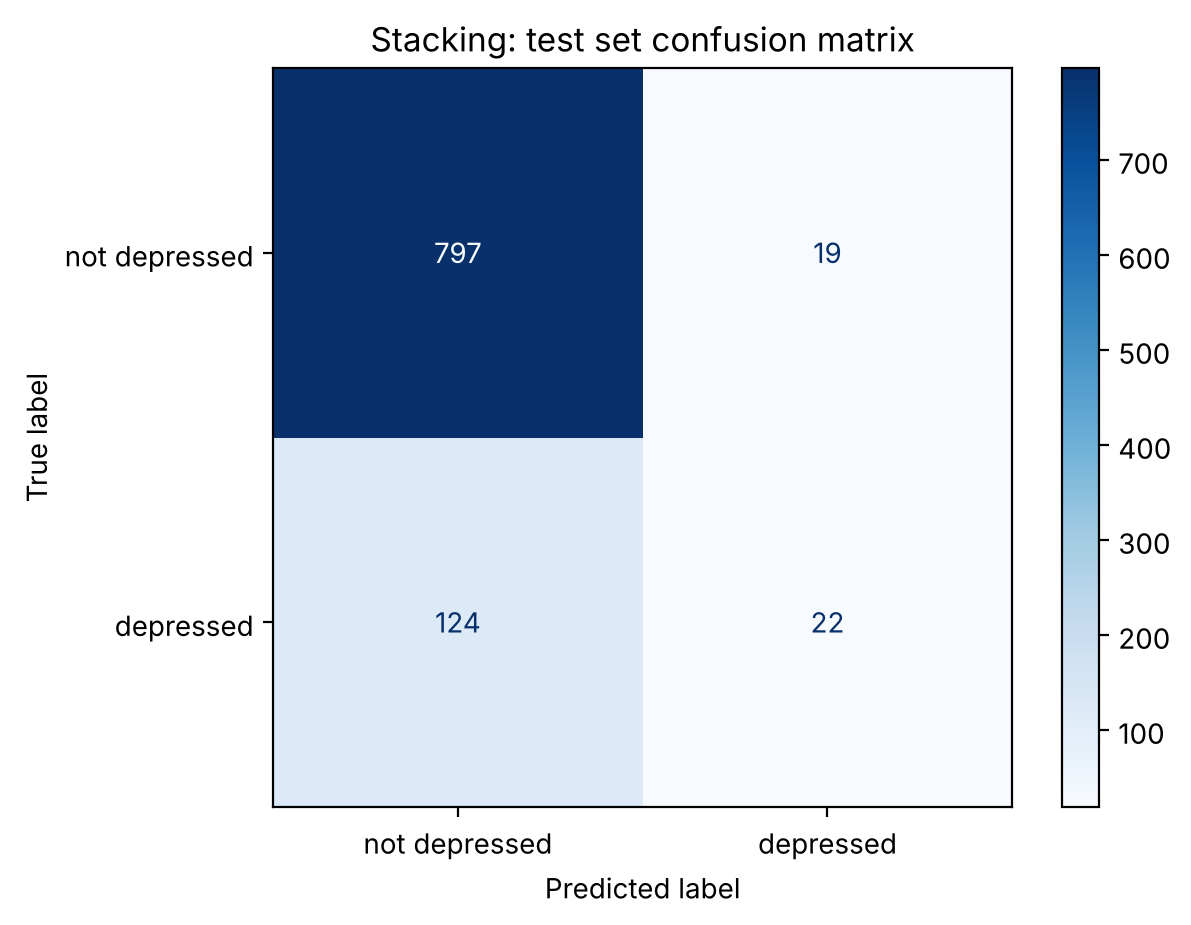

In [8]:
test_preds = {}
for name, make in model_makers.items():
    test_preds[name] = make().fit(X_trainval, y_trainval).predict(X_test)

print(f"Test baseline (always 'not depressed'): {(y_test == 0).mean():.3f}")
print(f"Real cases in the test set: {int(y_test.sum())}")
display(pd.DataFrame({name: scores(y_test, pred) for name, pred in test_preds.items()}).T.round(3))

stack_pred = test_preds["Stacking (logistic regression + KNN)"]
logreg_pred = test_preds["Logistic regression"]
print(f"Stacking and logistic regression give the same label to {(stack_pred == logreg_pred).mean():.1%} of test adolescents")
print("Flagged by stacking only:", int(((stack_pred == 1) & (logreg_pred == 0)).sum()),
      "| flagged by logistic regression only:", int(((stack_pred == 0) & (logreg_pred == 1)).sum()))

ConfusionMatrixDisplay.from_predictions(
    y_test, stack_pred, display_labels=["not depressed", "depressed"], cmap="Blues"
)
plt.title("Stacking: test set confusion matrix")
plt.show()

## **Explanation**

- **Stacking: accuracy 0.851, precision 0.537, recall 0.151, F1 0.235.** It flags 41 adolescents and catches 22 of the 146 real cases.
- **Confusion matrix:** 797 true negatives, 19 false positives, 124 false negatives, 22 true positives.
- **It gives the same label as logistic regression to 99.6% of test adolescents.** The only difference is four adolescents that logistic regression flags and the stack does not (one of them a real case, so logistic regression catches 23 and the stack 22).
- **F1 is between the two base models** (logistic regression 0.241, KNN 0.233), and within 0.01 of both.
- The test results confirm the validation and cross-validation results: combining the two models gives essentially logistic regression, with no gain.

> **Caveat:** as in `evaluation.ipynb`, this test set was already used in the earlier model notebooks. Nothing in this notebook was chosen from it; the comparison rests on the validation set and cross-validation.

---
## Step 9. Compiling the evidence for the final model choice

This step puts every candidate from the project through the same three checks, so the choice rests on one table. The neural network from `neural_network.ipynb` (Week 9) is included because `evaluation.ipynb` found it competitive. The decision tree and random forest are left out: the group ruled out the tree, and `evaluation.ipynb` and `model_comparison.ipynb` showed the forest does not improve on logistic regression.

The table also records the qualities that matter when the scores are close: how many false alarms each model raises, whether it overfits, and whether it can show which factors matter, which is what the research question asks.

,Validation F1,CV F1 mean,CV F1 SD,Test F1,Test precision,Test recall,Test false alarms,Train-validation accuracy gap,Shows which factors matter?
Logistic regression,0.249,0.220,0.037,0.241,0.511,0.158,22.0,-0.004,Yes (coefficients)
KNN (k = 5),0.248,0.236,0.026,0.233,0.362,0.171,44.0,0.032,No
Stacking (logistic regression + KNN),0.234,0.198,0.039,0.235,0.537,0.151,19.0,-0.003,Indirectly (mostly logistic regression)
Neural network (MLP),0.256,0.254,0.032,0.288,0.421,0.219,44.0,0.006,No


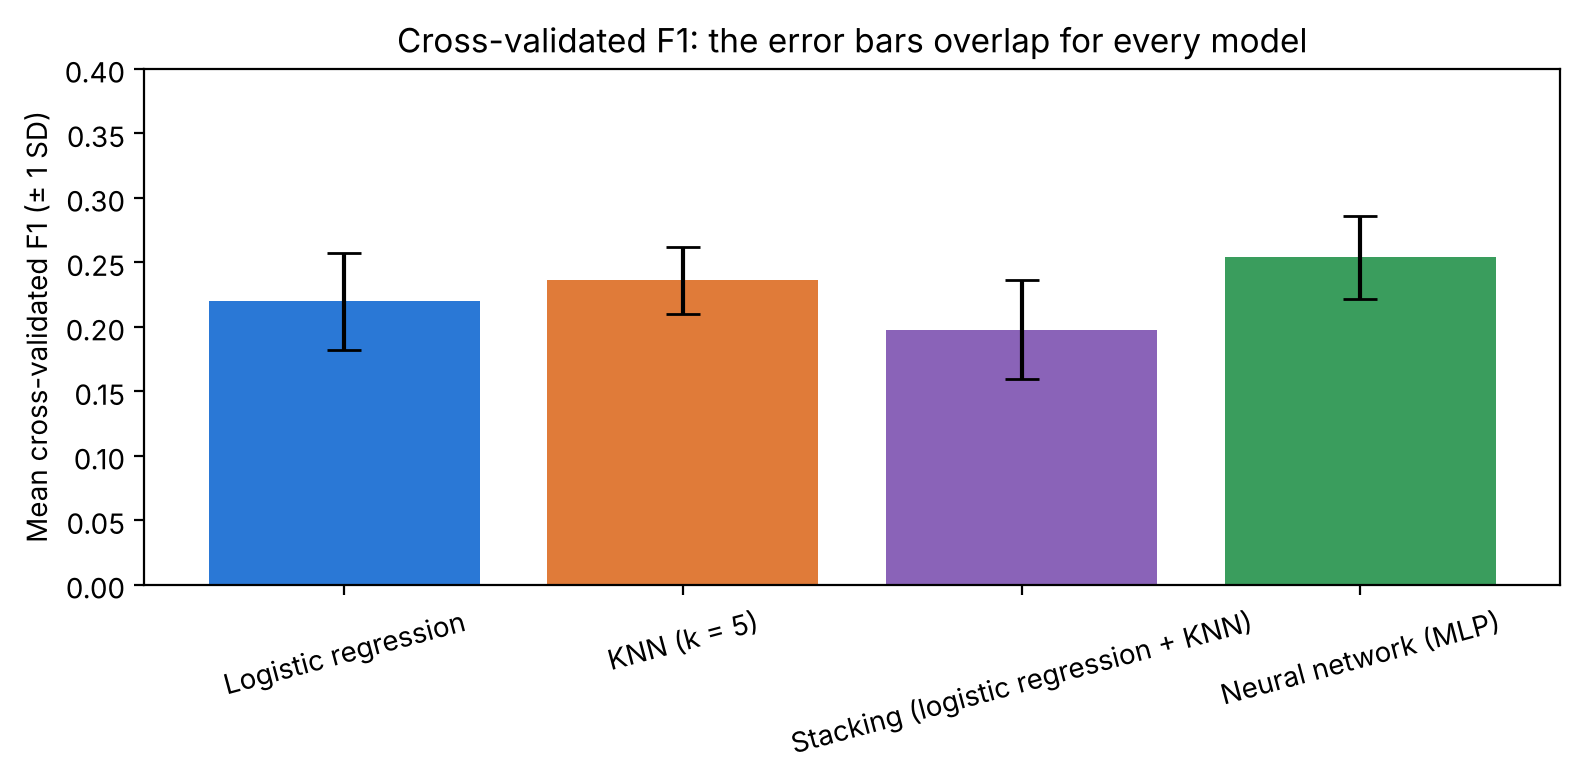

In [9]:
def make_mlp():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(12,), activation="relu", solver="adam",
            alpha=0.0001, learning_rate_init=0.01, max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ])

candidates = {**model_makers, "Neural network (MLP)": make_mlp}

evidence = {}
for name, make in candidates.items():
    valid_model = make().fit(X_train, y_train)
    valid_pred = valid_model.predict(X_valid)
    cv_f1 = cross_validate(make(), X_train, y_train, cv=cv, scoring="f1")["test_score"]
    test_pred = make().fit(X_trainval, y_trainval).predict(X_test)
    evidence[name] = {
        "Validation F1": f1_score(y_valid, valid_pred),
        "CV F1 mean": cv_f1.mean(),
        "CV F1 SD": cv_f1.std(),
        "Test F1": f1_score(y_test, test_pred),
        "Test precision": precision_score(y_test, test_pred),
        "Test recall": recall_score(y_test, test_pred),
        "Test false alarms": int(((test_pred == 1) & (y_test == 0)).sum()),
        "Train-validation accuracy gap": accuracy_score(y_train, valid_model.predict(X_train))
                                         - accuracy_score(y_valid, valid_pred),
    }

evidence = pd.DataFrame(evidence).T
evidence["Shows which factors matter?"] = ["Yes (coefficients)", "No", "Indirectly (mostly logistic regression)", "No"]
display(evidence.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
order = list(evidence.index)
ax.bar(order, evidence["CV F1 mean"], yerr=evidence["CV F1 SD"], capsize=6,
       color=["#2a78d6", "#e07b39", "#8a63b8", "#3a9d5d"])
ax.set_ylabel("Mean cross-validated F1 (± 1 SD)")
ax.set_title("Cross-validated F1: the error bars overlap for every model")
ax.set_ylim(0, 0.4)
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig("stacking_model_choice_f1.png", dpi=200, bbox_inches="tight")
plt.show()

## **Explanation**

**F1 (the group's chosen metric)**
- **The neural network has the highest F1 on all three checks:** validation 0.256, cross-validation 0.254, test 0.288.
- **Every lead is small.** Its cross-validated lead over logistic regression is 0.034, about one standard deviation, and the error bars in the chart overlap for every model. Logistic regression, KNN and the neural network are close to tied; stacking is slightly behind.

**When F1 does not separate the models**
- **False alarms:** the stack (19) and logistic regression (22) raise the fewest; KNN and the neural network raise twice as many (44 each). The neural network's extra recall comes with those extra false alarms.
- **Overfitting:** none of the four overfits. KNN has the largest train–validation gap (0.032).
- **Interpretability:** only logistic regression shows which factors matter, through its coefficients. The research question asks *what factors* predict crossing the threshold, so this counts.
- **Complexity:** stacking adds a second layer of models and gains nothing over logistic regression alone.
- `model_comparison.ipynb` (Step 6) also showed that logistic regression with a threshold of 0.4 catches the same 32 test cases as the neural network, with fewer false alarms. Most of the network's extra recall comes from where it draws the line.

---
## Summary: stacking and the final model choice

**Does stacking help?** No.
- Stacking logistic regression and KNN gave F1 0.234 on the validation set, 0.198 in cross-validation and 0.235 on the test set, never better than the best single model.
- The meta-learner gave logistic regression about nine times the weight of KNN (4.56 against 0.53), so the stack behaves like logistic regression: it gives the same label to 99.6% of test adolescents.
- Both base models are limited by the same seven features, and KNN's coarse probabilities add mostly noise, so there is nothing for the combination to add.

**Which model to pick: logistic regression.**

| | Logistic regression | KNN (k = 5) | Stacking | Neural network |
|---|---|---|---|---|
| Validation F1 | 0.249 | 0.248 | 0.234 | 0.256 |
| Cross-validated F1 (mean ± SD) | 0.220 ± 0.037 | 0.236 ± 0.026 | 0.198 ± 0.039 | 0.254 ± 0.032 |
| Test F1 | 0.241 | 0.233 | 0.235 | 0.288 |
| Test false alarms | 22 | 44 | 19 | 44 |
| Shows which factors matter | Yes | No | Mostly via logistic regression | No |

1. **On F1, the models are close to tied.** The differences are within the fold-to-fold variation, so F1 alone does not justify a more complex model.
2. **Logistic regression has half the false alarms** of KNN and the neural network, and does not overfit.
3. **It answers the research question directly:** its coefficients show which factors (sleep quality and sex most strongly) push the probability up.
4. **Stacking adds complexity without any gain**, and is essentially logistic regression in disguise.

**The alternative.** If the group decides that catching as many adolescents above the threshold as possible matters more than interpretability or false alarms, the neural network is the defensible choice: it leads on F1 in every check, although never by more than the noise. A similar gain is available from logistic regression with a lower threshold (`model_comparison.ipynb`, Step 6).

**One sentence for the presentation:** "We tested stacking logistic regression with KNN, but it didn't improve F1 and the meta-learner relied almost entirely on logistic regression, so we chose logistic regression alone: it was tied with the other models on F1, raised the fewest false alarms and lets us see which factors matter."